# Reinforcement learning for PID tuning — the third-order lag

**Plant** $\;P(s)=\dfrac{1}{(s+1)^3}$ $\qquad$ **Controller** (parallel form) $\;C(s)=K_p+\dfrac{K_i}{s}+K_d\,s$

You already know how to tune this loop with Ziegler–Nichols (ZN): find the ultimate gain $K_u$ and the
ultimate period $T_u$, then read three gains off a table. This notebook asks a different question:

> *What does it mean to let a learning agent tune the loop, and what does it buy us over ZN or over
> an ordinary optimiser?*

We go through the whole process, one step at a time, and every step runs in this notebook:

| § | Step | What you get |
|---|---|---|
| 1 | The plant and its ultimate point | $K_u$, $T_u$ by hand and numerically |
| 2 | Ziegler–Nichols baseline | the reference controller and its 46 % overshoot |
| 3 | An exact closed-loop simulator | the "environment" every agent interacts with |
| 4 | Writing the reward | the most important design decision in the whole lecture |
| 5 | The reward landscape | why the problem is hard: a stability cliff |
| 6 | Three ways to cast tuning as RL | one-shot, learned tuning rule, iterative tuner |
| 7 | **A** — REINFORCE on one plant | policy gradient by hand, in NumPy |
| 8 | A family of plants | why one plant is not enough |
| 9 | **B** — learning a tuning rule | a policy network that replaces the ZN table |
| 10 | **C** — iterative tuning with PPO | an agent that tunes like an engineer |
| 11 | Head to head on 200 unseen plants | the scorecard |
| 12 | Verify before you deploy | gain/phase margin and peak sensitivity |
| 13–15 | Protocol, exercises, references | |

**Learning objectives.** After this notebook you should be able to (1) formulate PID tuning as an MDP
in at least three different ways and say what the state, action, reward and episode are in each;
(2) write a reward that encodes a control specification, and predict what goes wrong when a term is
missing; (3) derive and implement the REINFORCE gradient for a Gaussian policy; (4) train a
contextual policy and a PPO agent with PyTorch; (5) judge honestly when RL is the right tool and when
a plain optimiser is better.

**Prerequisites.** Laplace transforms, state-space models, PID and Ziegler–Nichols tuning; the MDP,
policy-gradient and PPO material from the previous RL lecture (quadrotor hover).

**A note on the derivative term.** An ideal $K_d s$ cannot be built (it is improper) and a set-point
step would send an infinite impulse to the actuator. Every real PID, and every simulation in this
notebook, therefore uses the filtered form

$$C(s)=K_p+\frac{K_i}{s}+\frac{K_d\,s}{T_f\,s+1},\qquad T_f = T_u/36\approx 0.10\ \text{s for the nominal plant.}$$

$T_f$ is fixed, not tuned. For frequencies well below $1/T_f$ the two forms are identical.

In [1]:
import sys, time, json, platform
import numpy as np, scipy, matplotlib, torch
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.optimize import brentq, minimize
import torch.nn as nn

torch.set_num_threads(2)
np.set_printoptions(precision=4, suppress=True)
SURF, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "font.size": 11,
                     "axes.grid": True, "grid.color": GRID, "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False, "lines.linewidth": 2.0})
print("python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| torch", torch.__version__)
T_START = time.time()

python 3.13.18 | numpy 2.5.3 | scipy 1.18.1 | matplotlib 3.11.2 | torch 2.15.0+cu132


## 1. The plant and its ultimate point

Three identical first-order lags in series. Each contributes up to $-90^\circ$ of phase, so the
open loop reaches $-180^\circ$ at a finite frequency, and that is what makes a P-controller oscillate
when the gain is high enough.

**By hand.** With $P(j\omega)=1/(1+j\omega)^3$:

* phase $=-3\arctan\omega=-180^\circ \;\Rightarrow\; \arctan\omega_u=60^\circ \;\Rightarrow\; \omega_u=\sqrt3=1.732$ rad/s
* magnitude $|P(j\omega_u)|=(1+\omega_u^2)^{-3/2}=4^{-3/2}=1/8$

so the ultimate gain is $K_u=8$ and the ultimate period is $T_u=2\pi/\sqrt3=3.628$ s.

In the plant room you would measure $(K_u,T_u)$ with a **relay test** (Åström & Hägglund, 1984):
replace the controller with a relay and the loop settles into a limit cycle at $\omega_u$. The relay
test is safe, automatic and takes a few periods. Later in the notebook it is also how our learned
tuning rule "sees" an unfamiliar plant.

The code below covers the general case $P(s)=K/\prod_i(\tau_i s+1)$, which we will need from §8 on.

In [2]:
SEG_TU = 10.0


N_PER_TU = 60


TF_TU = 1.0 / 36.0


D_STEP = 0.5


W_OS, W_NOISE = 2.0, 0.01


J_FAIL = 20.0

In [3]:
def ultimate(K, taus):
    '''Ultimate gain Ku and period Tu (what a relay test measures).'''
    taus = np.asarray(taus, float)
    phase = lambda w: np.sum(np.arctan(w * taus)) - np.pi
    wu = brentq(phase, 1e-6, 1e6)
    mag = K / np.prod(np.sqrt(1 + (wu * taus) ** 2))
    return 1.0 / mag, 2 * np.pi / wu


K0, TAU0 = 1.0, (1.0, 1.0, 1.0)
Ku, Tu = ultimate(K0, TAU0)
print(f"Ku = {Ku:.4f}   (hand: 8)      Tu = {Tu:.4f} s   (hand: 2*pi/sqrt(3) = {2*np.pi/np.sqrt(3):.4f})")

Ku = 8.0000   (hand: 8)      Tu = 3.6276 s   (hand: 2*pi/sqrt(3) = 3.6276)


## 2. The Ziegler–Nichols baseline

ZN (1942) is a **tuning rule**: a fixed map from two measured numbers $(K_u,T_u)$ to three gains. In
ideal (ISA) form $K_p=aK_u$, $T_i=b_iT_u$, $T_d=b_dT_u$, which we convert to the parallel form with
$K_i=K_p/T_i$ and $K_d=K_pT_d$.

| rule | $a$ | $T_i/T_u$ | $T_d/T_u$ | designed for |
|---|---|---|---|---|
| classic | 0.60 | 0.50 | 0.125 | quarter-amplitude decay of a **load** disturbance |
| some overshoot | 0.33 | 0.50 | 0.33 | gentler set-point response |
| no overshoot | 0.20 | 0.50 | 0.33 | very gentle |

Keep the "designed for" column in mind. ZN classic was never meant to give a nice **set-point**
step. Its aggressive gains are a deliberate trade for fast load rejection.

The **test** used throughout the notebook has two segments: a unit set-point step at $t=0$, then a
load step $d=0.5/K$ at the plant input at $t=10\,T_u$, ending at $t=20\,T_u$. One experiment shows
both how the loop tracks and how it rejects a disturbance.

In [4]:
def zn_gains(Ku, Tu, rule="classic"):
    '''Ziegler-Nichols closed-loop rules, returned in parallel form (Kp, Ki, Kd).'''
    a, bi, bd = {"classic": (0.60, 0.5, 0.125),
                 "some_os": (0.33, 0.5, 0.333),
                 "no_os":   (0.20, 0.5, 0.333)}[rule]
    Kp = a * Ku
    Ti, Td = bi * Tu, bd * Tu
    return np.array([Kp, Kp / Ti, Kp * Td])


for rule in ["classic", "some_os", "no_os"]:
    Kp, Ki, Kd = zn_gains(Ku, Tu, rule)
    print(f"ZN {rule:8s}:  Kp = {Kp:.3f}   Ki = {Ki:.3f}   Kd = {Kd:.3f}")

ZN classic :  Kp = 4.800   Ki = 2.646   Kd = 2.177
ZN some_os :  Kp = 2.640   Ki = 1.456   Kd = 3.189
ZN no_os   :  Kp = 1.600   Ki = 0.882   Kd = 1.933


## 3. An exact closed-loop simulator: the environment

Every RL method below interacts with the loop only through **experiments**: apply some gains, run
the two-segment test, measure the response. So the simulator is the RL *environment*, and it has
to be right.

**State-space form.** Write the plant as a cascade of lags, $\dot x_1=(u+d-x_1)/\tau_1$,
$\dot x_2=(x_1-x_2)/\tau_2$, $\dot x_3=(x_2-x_3)/\tau_3$, $y=Kx_3$. The controller adds an integrator
state $\dot x_i=e$ and a derivative-filter state $\dot x_f=(e-x_f)/T_f$. Since

$$\frac{K_d s}{T_f s+1}e=\frac{K_d}{T_f}\,(e-x_f),$$

the control law is $u=(K_p+K_d/T_f)\,e+K_i x_i-(K_d/T_f)\,x_f$ with $e=r-y$. Collecting the five
states gives one linear system $\dot z=Az+B\,[r,\,d]^\top$.

**Exact discretisation.** The inputs are piecewise constant, so the zero-order-hold solution is
*exact*, not an approximation. One matrix exponential of the augmented matrix
$\begin{bmatrix}A&B\\0&0\end{bmatrix}\Delta t$ gives $A_d$ and $B_d$, and then
$z_{k+1}=A_dz_k+B_dw_k$. This avoids the step-size worries of Euler or RK4, which matter here
because the derivative filter is ten times faster than the plant.

**Stability is free.** A closed loop is unstable iff $A$ has an eigenvalue with non-negative real
part, so we check that before simulating and charge a fixed cost $J_\text{fail}$ instead.

**Time in units of $T_u$.** Sample time $\Delta t=T_u/60$ and segment length $10T_u$. For the nominal
plant that is 0.06 s and 36.3 s. Scaling by $T_u$ makes the experiment the same *shape* for fast and
slow plants, which §8 relies on.

In [5]:
def closed_loop(K, taus, gains, Tf):
    '''State z = [x1, x2, x3, xi, xf]; inputs [r, d]. Returns A, B, and
    row vectors (Cy, Dy), (Cu, Du) so that y = Cy z, u = Cu z + Du [r, d].'''
    t1, t2, t3 = taus
    Kp, Ki, Kd = gains
    kd = Kd / Tf
    # e = r - K x3 ;  u = (Kp + kd) e + Ki xi - kd xf
    Cu = np.array([0, 0, -(Kp + kd) * K, Ki, -kd])
    Du = np.array([Kp + kd, 0.0])
    A = np.zeros((5, 5)); B = np.zeros((5, 2))
    A[0] = Cu / t1;      A[0, 0] -= 1 / t1
    B[0] = (Du + np.array([0, 1.0])) / t1           # plant input = u + d
    A[1, 0], A[1, 1] = 1 / t2, -1 / t2
    A[2, 1], A[2, 2] = 1 / t3, -1 / t3
    A[3, 2] = -K;  B[3, 0] = 1                       # xi' = e
    A[4, 2] = -K / Tf; A[4, 4] = -1 / Tf; B[4, 0] = 1 / Tf   # xf' = (e - xf)/Tf
    Cy = np.array([0, 0, K, 0, 0.0])
    return A, B, Cy, Cu, Du


def simulate(K, taus, gains, Ku=None, Tu=None):
    '''Exact (zero-order-hold) simulation of the two-segment test.'''
    if Tu is None:
        Ku, Tu = ultimate(K, taus)
    Tf = TF_TU * Tu
    A, B, Cy, Cu, Du = closed_loop(K, taus, gains, Tf)
    stable = np.max(np.linalg.eigvals(A).real) < -1e-9
    dt = Tu / N_PER_TU
    n_seg = int(SEG_TU * N_PER_TU)
    M = np.zeros((7, 7)); M[:5, :5] = A; M[:5, 5:] = B
    E = expm(M * dt); Ad, Bd = E[:5, :5], E[:5, 5:]
    n = 2 * n_seg + 1
    t = np.arange(n) * dt
    r = np.ones(n); d = np.where(np.arange(n) >= n_seg, D_STEP / K, 0.0)
    z = np.zeros(5); Y = np.zeros(n); U = np.zeros(n)
    for k in range(n):
        w = np.array([r[k], d[k]])
        Y[k] = Cy @ z; U[k] = Cu @ z + Du @ w
        z = Ad @ z + Bd @ w
        if not np.isfinite(z).all() or abs(Y[k]) > 1e6:
            Y[k:] = np.nan; U[k:] = np.nan; break
    out = dict(t=t, y=Y, u=U, r=r, d=d, Tu=Tu, Ku=Ku, stable=stable, n_seg=n_seg, dt=dt)
    out.update(metrics(out, K, gains, Tf))
    return out


def metrics(sim, K, gains, Tf):
    y, dt, n_seg, Tu = sim["y"], sim["dt"], sim["n_seg"], sim["Tu"]
    if not sim["stable"] or not np.isfinite(y).all():
        return dict(J=J_FAIL, iae_r=np.nan, iae_d=np.nan, os=np.nan, ts=np.nan,
                    noise=np.nan, tr=np.nan)
    e = 1.0 - y
    iae_r = np.sum(np.abs(e[:n_seg])) * dt / Tu
    iae_d = np.sum(np.abs(e[n_seg:])) * dt / Tu
    os_ = max(0.0, np.max(y[:n_seg]) - 1.0)
    Kp, Ki, Kd = gains
    noise = K * (Kp + Kd / Tf)                       # loop gain to sensor noise at high frequency
    J = iae_r + iae_d + W_OS * os_ + W_NOISE * noise
    seg = y[:n_seg]; tt = sim["t"][:n_seg]
    out_band = np.where(np.abs(seg - 1) > 0.02)[0]
    ts = tt[out_band[-1]] if len(out_band) else 0.0
    i10 = np.argmax(seg >= 0.1); i90 = np.argmax(seg >= 0.9)
    tr = tt[i90] - tt[i10] if seg.max() >= 0.9 else np.nan
    return dict(J=min(J, J_FAIL), iae_r=iae_r, iae_d=iae_d, os=os_, ts=ts, noise=noise, tr=tr)

**Check the simulator against an independent method.** We form the closed-loop transfer function
$T(s)=PC/(1+PC)$ by polynomial algebra and let `scipy.signal` compute its step response. If the two
differ by more than rounding error, nothing that follows can be trusted.

In [6]:
from scipy import signal
g_zn = zn_gains(Ku, Tu)
Kp, Ki, Kd = g_zn; Tf = TF_TU * Tu
# C(s) = [Kp s (Tf s+1) + Ki (Tf s+1) + Kd s^2] / [s (Tf s+1)],  P(s) = 1/(s+1)^3
numC = np.polyadd(np.polyadd(Kp * np.array([Tf, 1, 0]), Ki * np.array([Tf, 1])), [Kd, 0, 0])
denC = np.array([Tf, 1, 0]); numP, denP = [1.0], np.poly([-1, -1, -1])
num = np.polymul(numC, numP); den = np.polyadd(np.polymul(denC, denP), num)
sim = simulate(K0, TAU0, g_zn)
n = sim["n_seg"]
_, y_ref = signal.step(signal.lti(num, den), T=sim["t"][:n])
print("max |y_statespace - y_transferfunction| =", f"{np.max(np.abs(sim['y'][:n] - y_ref)):.2e}")
print("closed loop stable:", sim["stable"], "  overshoot:", f"{100*sim['os']:.1f} %",
      "  2 % settling time:", f"{sim['ts']:.2f} s")

max |y_statespace - y_transferfunction| = 3.22e-15
closed loop stable: True   overshoot: 46.0 %   2 % settling time: 9.01 s


The two methods agree to rounding error. Now the ZN responses, together with the P-only experiment
that produced $(K_u,T_u)$.

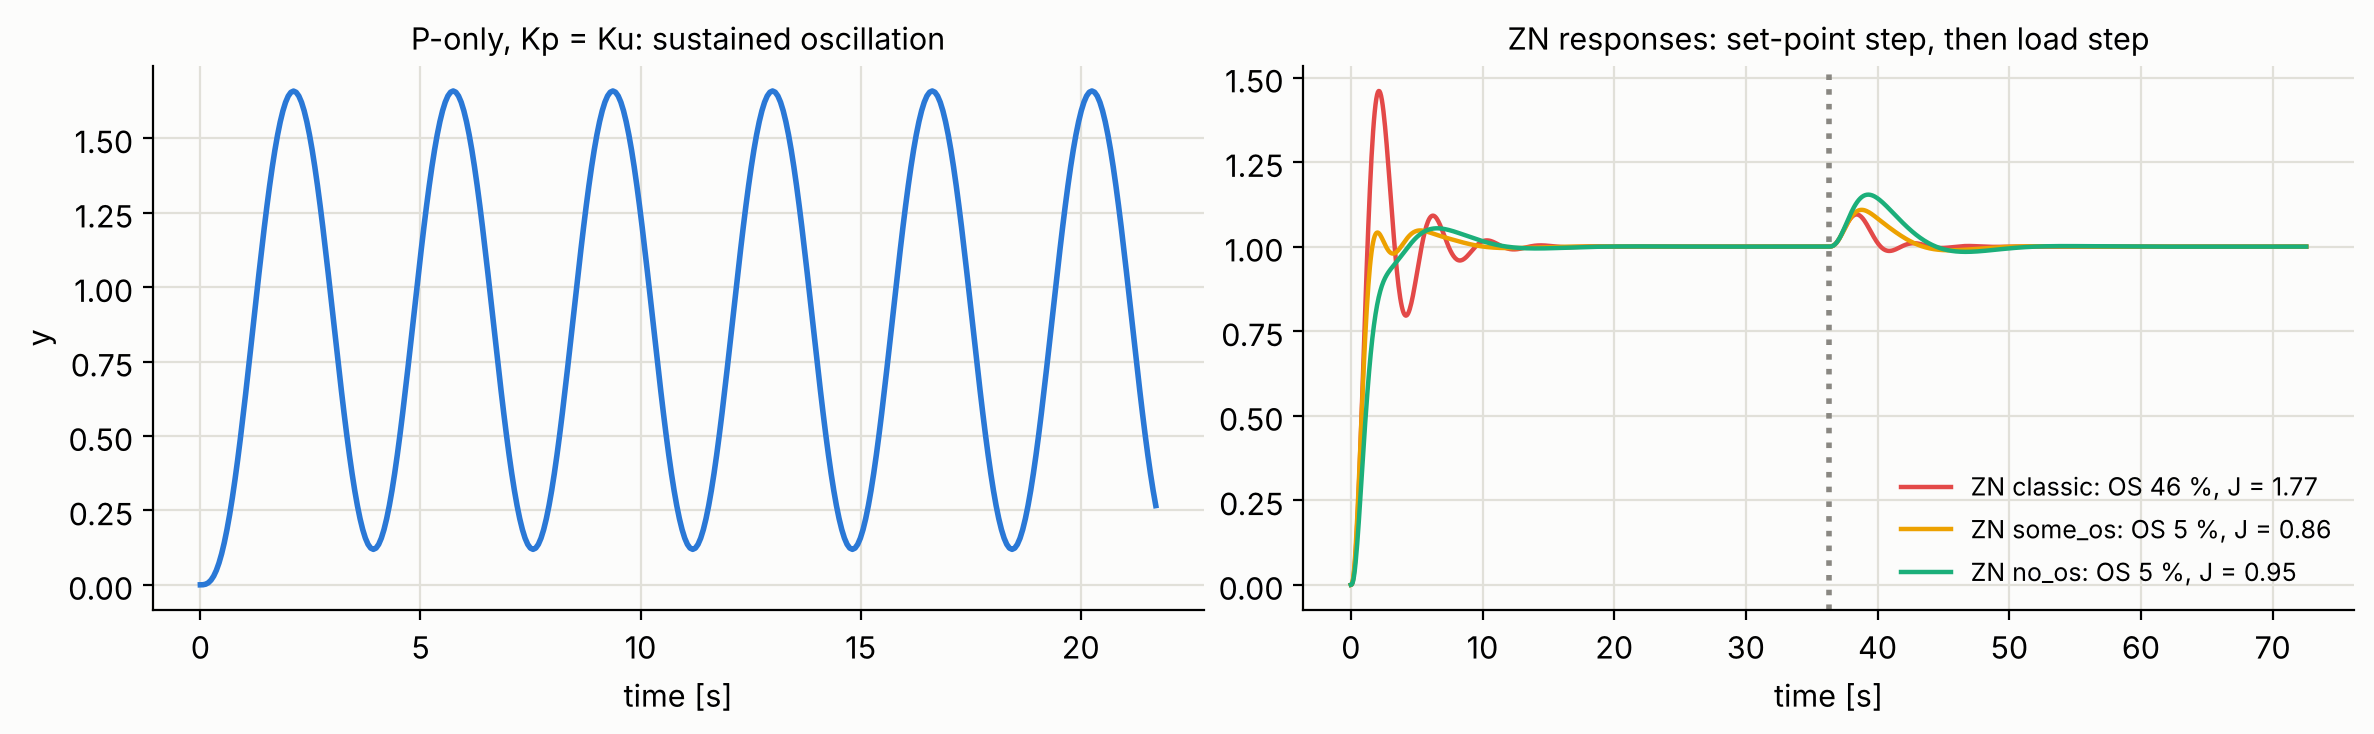

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
s = simulate(K0, TAU0, np.array([Ku, 0, 0])); m = s["t"] < 6 * Tu
ax[0].plot(s["t"][m], s["y"][m], color=BLUE); ax[0].set_title("P-only, Kp = Ku: sustained oscillation", fontsize=11)
ax[0].set_xlabel("time [s]"); ax[0].set_ylabel("y")
for rule, c in [("classic", RED), ("some_os", YELLOW), ("no_os", AQUA)]:
    s = simulate(K0, TAU0, zn_gains(Ku, Tu, rule))
    ax[1].plot(s["t"], s["y"], color=c, lw=1.6, label=f"ZN {rule}: OS {100*s['os']:.0f} %, J = {s['J']:.2f}")
ax[1].axvline(s["t"][s["n_seg"]], color=MUTED, ls=":"); ax[1].legend(fontsize=9)
ax[1].set_xlabel("time [s]"); ax[1].set_title("ZN responses: set-point step, then load step", fontsize=11)
plt.tight_layout(); plt.show()

ZN classic overshoots by about **46 %** and rings, but it rejects the load step quickly and with
little deviation, which is exactly what it was designed for. The two gentler variants trade some
load rejection for a calmer set-point response. *Which is best?* That question has no answer until
we write down what "best" means, and writing that down is the reward.

## 4. Writing the reward: the most important design decision

An RL agent maximises **exactly** the number you hand it, nothing more. All of your control
engineering knowledge has to go into that number. We use a cost $J$ (reward $=-J$) with four terms,
each made dimensionless so that the same formula works for every plant in §8:

$$J=\underbrace{\frac{1}{T_u}\int_{\text{set-point}}|e|\,dt}_{\text{IAE}_r}
+\underbrace{\frac{1}{T_u}\int_{\text{load}}|e|\,dt}_{\text{IAE}_d}
+\;2\cdot\underbrace{\max(0,\,y_\text{max}-1)}_{\text{overshoot}}
+\;0.01\cdot\underbrace{K\left(K_p+\frac{K_d}{T_f}\right)}_{\text{noise gain}}$$

| term | engineering meaning | what happens if you leave it out |
|---|---|---|
| IAE$_r$ | fast, accurate tracking | nothing pushes the loop to move at all |
| IAE$_d$ | load rejection, ZN's own objective | set-point-only tuning with sluggish disturbance recovery |
| overshoot | product spec, mechanical limits | integral criteria happily accept 20–35 % overshoot |
| noise gain | how much sensor noise reaches the actuator, $\lvert C(j\infty)\rvert$ for the filtered PID | the optimiser buys a tiny IAE gain with a huge $K_d$, a chattering valve, worn actuators |
| $J_\text{fail}=20$ | unstable loop | the episode has no meaningful cost at all |

The noise-gain term is the high-frequency gain of the controller, $|C(j\omega)|\to K_p+K_d/T_f$ as
$\omega\to\infty$. We charge it directly rather than simulating noise, which keeps the reward
deterministic. Exercise 5 asks what changes when you simulate noise instead.

The vectorised `cost_batch` below evaluates $J$ for many (plant, gains) pairs in one call. RL needs
thousands of experiments, so this is where the runtime goes.

In [8]:
def cost_batch(K, taus, gains, Ku, Tu, w=(1.0, 1.0, W_OS, W_NOISE)):
    '''Vectorised cost for many (plant, gains) pairs.  Shapes: K (N,), taus (N,3),
    gains (N,3), Ku/Tu (N,).  w = weights on (IAE_r, IAE_d, overshoot, noise gain).
    Returns J (N,) and a dict of metric arrays.'''
    K = np.asarray(K, float); taus = np.asarray(taus, float); gains = np.asarray(gains, float)
    Ku = np.asarray(Ku, float); Tu = np.asarray(Tu, float)
    N = len(K)
    Tf = TF_TU * Tu
    dt = Tu / N_PER_TU
    n_seg = int(SEG_TU * N_PER_TU)
    Ad = np.zeros((N, 5, 5)); Bd = np.zeros((N, 5, 2))
    Cy = np.zeros((N, 5)); Cu = np.zeros((N, 5)); Du = np.zeros((N, 2))
    stable = np.zeros(N, bool)
    for i in range(N):
        A, B, cy, cu, du = closed_loop(K[i], taus[i], gains[i], Tf[i])
        stable[i] = np.max(np.linalg.eigvals(A).real) < -1e-9
        if not stable[i]:
            continue
        M = np.zeros((7, 7)); M[:5, :5] = A; M[:5, 5:] = B
        E = expm(M * dt[i]); Ad[i], Bd[i] = E[:5, :5], E[:5, 5:]
        Cy[i], Cu[i], Du[i] = cy, cu, du
    z = np.zeros((N, 5))
    absum_r = np.zeros(N); absum_d = np.zeros(N); ymax = np.zeros(N)
    w_r = np.stack([np.ones(N), np.zeros(N)], 1)
    w_d = np.stack([np.ones(N), D_STEP / K], 1)
    for k in range(2 * n_seg + 1):
        wk = w_r if k < n_seg else w_d
        y = np.einsum("ni,ni->n", Cy, z)
        if k < n_seg:
            absum_r += np.abs(1 - y); ymax = np.maximum(ymax, y)
        else:
            absum_d += np.abs(1 - y)
        z = np.einsum("nij,nj->ni", Ad, z) + np.einsum("nij,nj->ni", Bd, wk)
    iae_r = absum_r * dt / Tu; iae_d = absum_d * dt / Tu
    os_ = np.maximum(0, ymax - 1)
    noise = K * (gains[:, 0] + gains[:, 2] / Tf)
    J = w[0] * iae_r + w[1] * iae_d + w[2] * os_ + w[3] * noise
    J = np.where(stable & np.isfinite(J), np.minimum(J, J_FAIL), J_FAIL)
    return J, dict(iae_r=iae_r, iae_d=iae_d, os=os_, noise=noise, stable=stable)

**Experiment: four rewards, four controllers.** To isolate the reward from the learning algorithm,
we first find the *exact* optimum of each reward with a deterministic optimiser (Nelder–Mead on
$\log K$, two starting points). Watch what each missing term lets through.

In [9]:
def best_gains(w, starts):
    f = lambda lg: cost_batch([K0], [TAU0], [np.exp(np.clip(lg, -5, np.log(200)))], [Ku], [Tu], w)[0][0]
    best = None
    for x0 in starts:
        r = minimize(f, x0, method="Nelder-Mead", options=dict(xatol=1e-4, fatol=1e-7, maxiter=3000))
        if best is None or r.fun < best.fun: best = r
    return np.exp(np.clip(best.x, -5, np.log(200))), best.nfev

VARIANTS = {"IAE set-point only": (1, 0, 0, 0), "+ load IAE": (1, 1, 0, 0),
            "+ overshoot": (1, 1, W_OS, 0), "+ noise gain (full J)": (1, 1, W_OS, W_NOISE)}
starts = [np.log(zn_gains(Ku, Tu)), np.log(zn_gains(Ku, Tu, "no_os"))]
opt = {}
print(f"{'reward':24s} {'Kp':>6s} {'Ki':>6s} {'Kd':>6s} {'OS %':>6s} {'IAE_r':>6s} {'IAE_d':>6s} {'noise':>6s}")
for name, w in VARIANTS.items():
    g, nfev = best_gains(w, starts); opt[name] = g
    _, m = cost_batch([K0], [TAU0], [g], [Ku], [Tu])
    print(f"{name:24s} {g[0]:6.2f} {g[1]:6.2f} {g[2]:6.2f} {100*m['os'][0]:6.1f} {m['iae_r'][0]:6.3f} "
          f"{m['iae_d'][0]:6.3f} {m['noise'][0]:6.1f}")
g_opt = opt["+ noise gain (full J)"]
J_opt = cost_batch([K0], [TAU0], [g_opt], [Ku], [Tu])[0][0]
print(f"\nZN classic for reference: noise gain {cost_batch([K0],[TAU0],[g_zn],[Ku],[Tu])[1]['noise'][0]:.1f}, "
      f"J = {cost_batch([K0],[TAU0],[g_zn],[Ku],[Tu])[0][0]:.3f};   optimum of the full J = {J_opt:.4f}")

reward                       Kp     Ki     Kd   OS %  IAE_r  IAE_d  noise


IAE set-point only         4.22   1.70   5.45   16.6  0.262  0.090   58.3


+ load IAE                 5.88   4.03   7.66   34.9  0.279  0.047   81.9


+ overshoot                2.78   1.06   3.23    1.0  0.295  0.137   34.8


+ noise gain (full J)      2.20   0.85   1.74    0.4  0.342  0.164   19.5

ZN classic for reference: noise gain 26.4, J = 1.768;   optimum of the full J = 0.7075


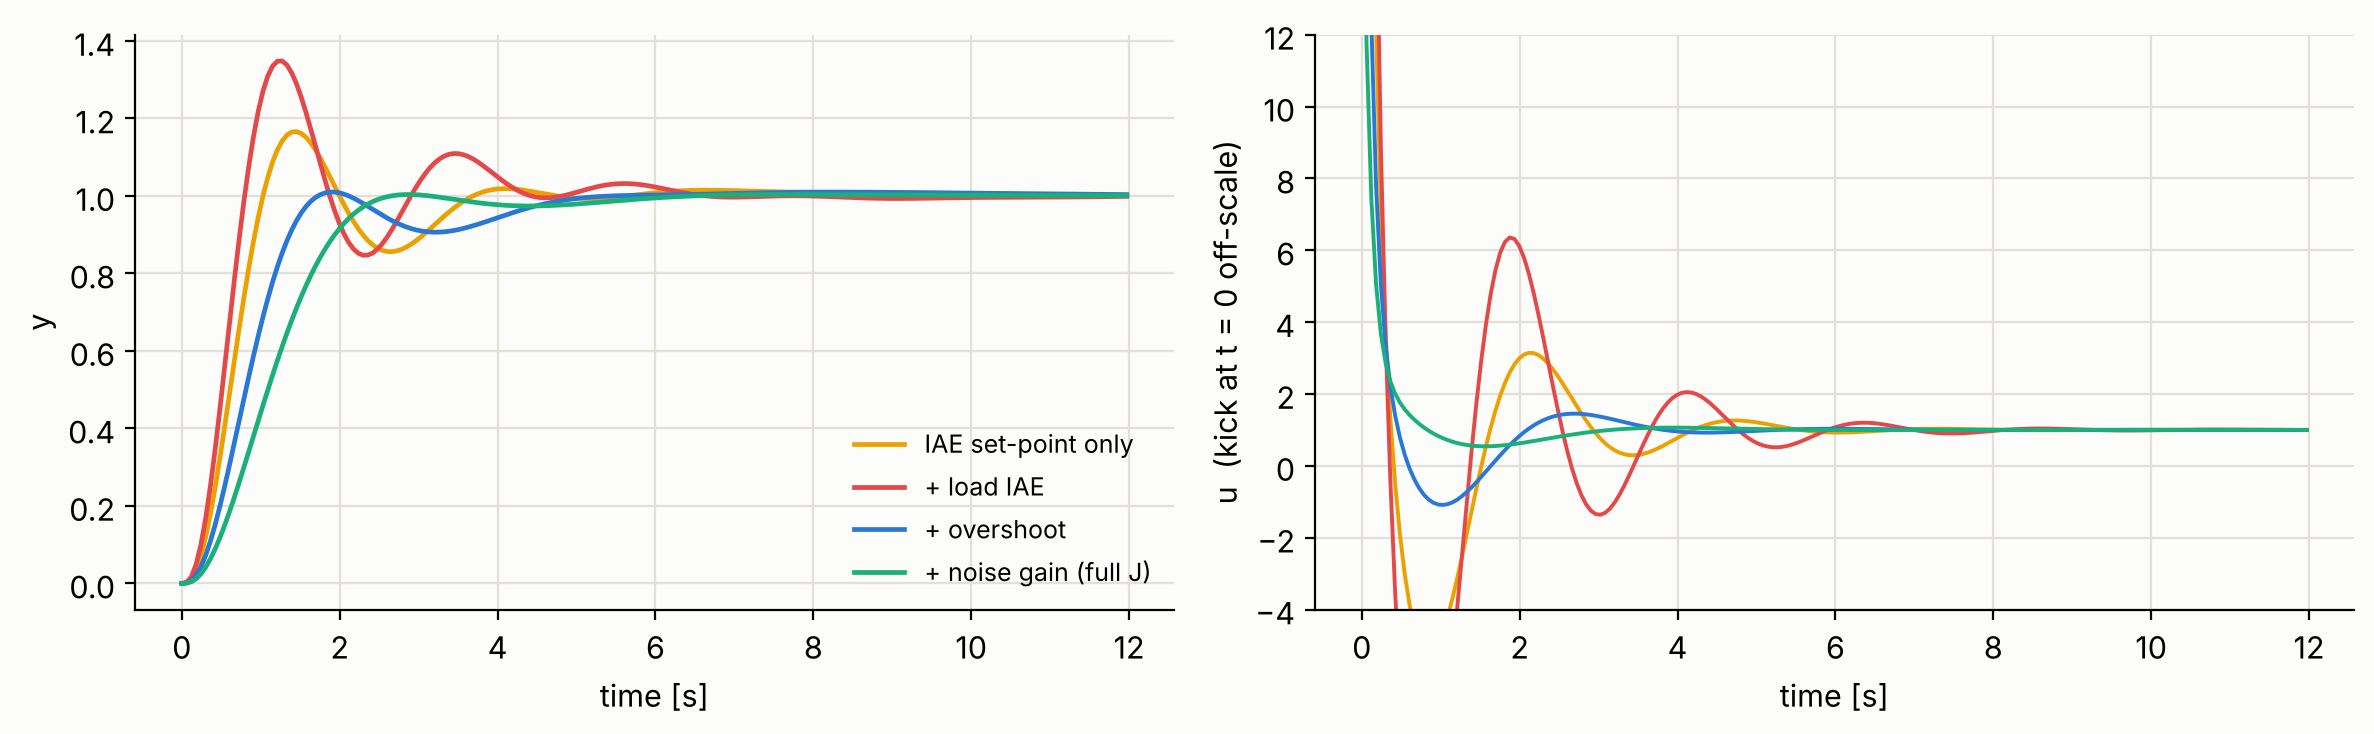

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for (name, g), c in zip(opt.items(), [YELLOW, RED, BLUE, AQUA]):
    s = simulate(K0, TAU0, g); m = s["t"] < 12
    ax[0].plot(s["t"][m], s["y"][m], color=c, lw=1.7, label=name)
    ax[1].plot(s["t"][m], s["u"][m], color=c, lw=1.4)
ax[0].legend(fontsize=9); ax[0].set_xlabel("time [s]"); ax[0].set_ylabel("y")
ax[1].set_ylim(-4, 12); ax[1].set_xlabel("time [s]"); ax[1].set_ylabel("u  (kick at t = 0 off-scale)")
plt.tight_layout(); plt.show()

**Read the table before moving on.** With only IAE$_r$ the "optimal" loop overshoots about 17 %
and amplifies sensor noise 2.2 times more than ZN. Adding load IAE makes it *worse* on both counts
(35 % overshoot, noise gain 82), because aggressive integral action rejects loads well. The
overshoot term tames the step, and only the noise term stops the derivative from growing. The final
controller has **0.4 %** overshoot and a *lower* noise gain than ZN.

This is the RL version of the old control proverb that you get the closed loop you specify. Every
later algorithm in this notebook optimises this same $J$, so whatever we learned here carries over:
**if a learned controller looks wrong, check the reward first.**

## 5. The reward landscape: why this is not an easy optimisation

A slice through $J$ over $(K_p,K_i)$ with $K_d$ fixed at its optimum shows two features that shape
every algorithmic choice below.

1. **The scales differ wildly and the useful region is roughly log-shaped.** That is why every agent
   in this notebook acts on $\theta=\log K$, not on $K$. Log-gains are also always positive, so a
   PID with a negative gain never has to be considered.
2. **A stability cliff.** Beyond a boundary the loop is unstable and $J$ jumps to a flat $J_\text{fail}$.
   On that plateau there is no gradient pointing back toward the stable region. A gradient-based
   tuner that steps over the edge is lost, and a *real* plant that is pushed over it may be
   damaged.

fraction of this (log-uniform) box that is unstable: 0.131


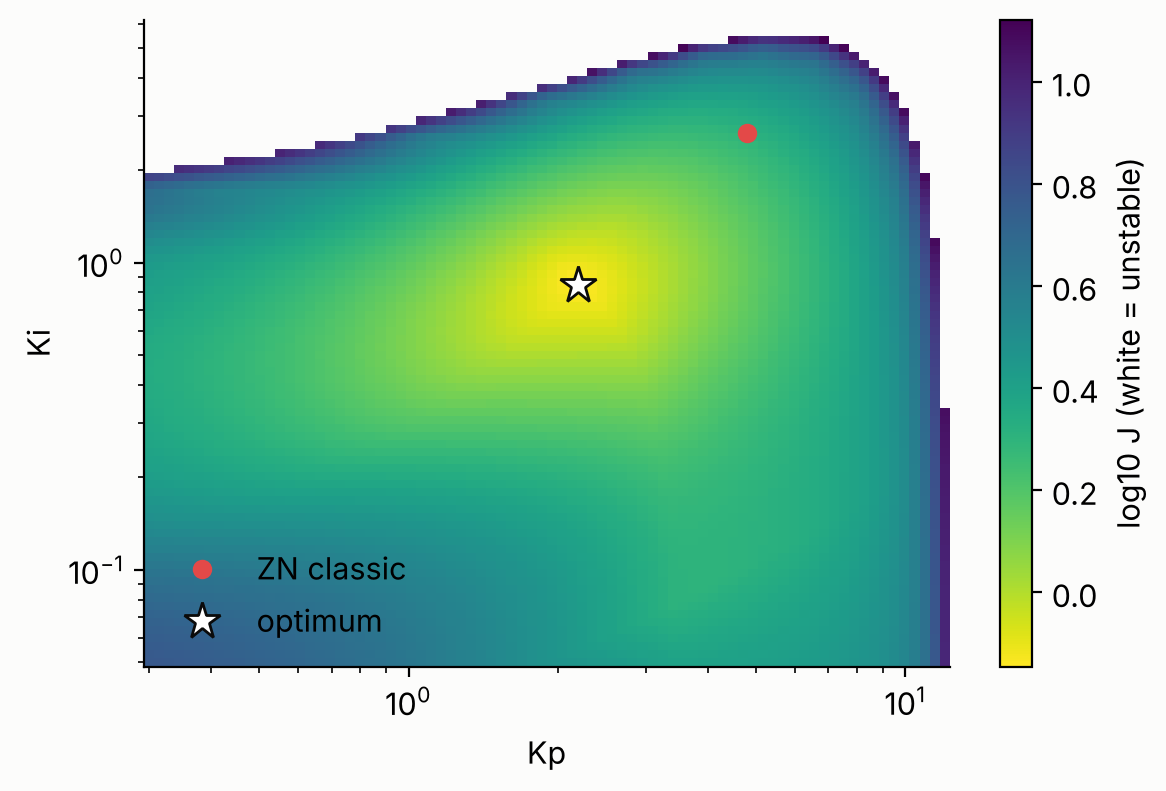

In [11]:
kp = np.exp(np.linspace(np.log(0.3), np.log(12), 80)); ki = np.exp(np.linspace(np.log(0.05), np.log(6), 80))
KP, KI = np.meshgrid(kp, ki)
G = np.stack([KP.ravel(), KI.ravel(), np.full(KP.size, g_opt[2])], 1)
Jg, mg = cost_batch(np.ones(len(G)), np.tile(TAU0, (len(G), 1)), G, np.full(len(G), Ku), np.full(len(G), Tu))
print(f"fraction of this (log-uniform) box that is unstable: {1 - mg['stable'].mean():.3f}")
fig, ax = plt.subplots(figsize=(6.5, 4.2))
cs = ax.pcolormesh(kp, ki, np.where(mg["stable"], np.log10(Jg), np.nan).reshape(KP.shape),
                   cmap="viridis_r", shading="auto")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Kp"); ax.set_ylabel("Ki"); ax.grid(False)
ax.plot(*g_zn[:2], "o", color=RED, label="ZN classic"); ax.plot(*g_opt[:2], "*", ms=14, color="white", mec=INK, label="optimum")
ax.legend(loc="lower left"); fig.colorbar(cs, label="log10 J (white = unstable)"); plt.show()

About **13 %** of this box is unstable. ZN classic sits close to the edge, which matches its
small phase margin (§12). The optimum lies well inside the stable region.

## 6. Three ways to cast PID tuning as reinforcement learning

"Use RL to tune a PID" can mean very different MDPs. Before writing any learning code, be explicit
about the state, action, reward and episode:

| | **A — one plant, one shot** | **B — a learned tuning rule** | **C — iterative tuning** |
|---|---|---|---|
| state $s$ | none (a bandit) | plant features from a relay + step test | gains so far + metrics of the last experiment |
| action $a$ | $\log(K_p,K_i,K_d)$ | log-multipliers on the ZN gains | *change* in the log-multipliers ($\pm0.4$) |
| reward | $-J$ | $\log(J_\text{ZN}/J)$ | $\log(J_\text{prev}/J_\text{new})$ |
| episode | 1 experiment | 1 experiment on a random plant | 6 experiments on one plant |
| algorithm here | REINFORCE (NumPy) | policy gradient + critic (PyTorch) | PPO (PyTorch) |
| analogy | trial and error | a better ZN table | an engineer at the panel |

A fourth family exists, in which RL **replaces** or **schedules** the PID at every sample time
(state = the process signals, action = $u$ or the gains at 50 Hz). It is a different problem,
continuous control with all the sim-to-real issues of the quadrotor lecture, and we do not cover it
here.

A and B are *contextual bandits*. Each episode is a single decision, so there is no credit
assignment through time and the "RL" is in the policy-gradient estimator and the exploration. C is a
genuine multi-step MDP, because the agent's early experiments change what it knows when it makes
later ones.

## 7. Formulation A — REINFORCE on one plant

**Policy.** A diagonal Gaussian over log-gains, $\theta\sim\pi_\phi=\mathcal N(\mu,\operatorname{diag}\sigma^2)$
with parameters $\phi=(\mu,\log\sigma)$, six numbers in total. One episode samples $\theta$, runs one
experiment and returns $R=-J(e^\theta)$.

**Objective and gradient.** We maximise $\mathcal J(\phi)=\mathbb E_{\theta\sim\pi_\phi}[R(\theta)]$.
The *score-function* (likelihood-ratio) identity $\nabla_\phi\mathbb E[R]=\mathbb E[R\,\nabla_\phi\log\pi_\phi(\theta)]$
needs no derivative of $R$. That is essential here, because $J$ is flat on the unstable plateau and
non-smooth at the overshoot kink. For the Gaussian, writing $\theta=\mu+\sigma\odot\varepsilon$:

$$\nabla_\mu\log\pi=\frac{\varepsilon}{\sigma},\qquad \nabla_{\log\sigma}\log\pi=\varepsilon^2-1.$$

**Variance reduction.** Subtract a baseline (the batch mean reward), which leaves the expectation
unchanged, and divide by the batch standard deviation. The resulting advantages
$A_i=(R_i-\bar R)/\operatorname{std}(R)$ are invariant to the scale of $J$. Then

$$\hat g_\mu=\frac1N\sum_i A_i\,\frac{\varepsilon_i}{\sigma},\qquad
\hat g_{\log\sigma}=\frac1N\sum_i A_i(\varepsilon_i^2-1),$$

followed by an Adam step. Learning $\sigma$ lets the policy *decide how much to explore*: it widens
when a direction looks promising and narrows as it converges. This estimator is the same as a
natural-evolution-strategy update, and RL and black-box optimisation meet exactly here (Salimans
et al., 2017).

**Start at ZN.** $\mu_0=\log K_\text{ZN}$ and $\sigma_0=0.3$ (about ±35 %). Starting from a known,
stable controller is the single most important safety measure when the "environment" is a real
plant.

In [12]:
def reinforce_one_plant(K, taus, Ku, Tu, mu0, sigma0=0.3, iters=80, batch=32,
                        lr=0.05, seed=0):
    '''Gaussian policy over theta = log(gains). One episode = one closed-loop step test.
    Returns a history dict.  Pure NumPy: the policy has only 6 parameters.'''
    rng = np.random.default_rng(seed)
    mu = np.array(mu0, float); log_sig = np.full(3, np.log(sigma0))
    m = np.zeros(6); v = np.zeros(6); b1, b2 = 0.9, 0.999
    H = dict(mu=[], sigma=[], J_mean=[], J_mu=[], frac_unstable=[], evals=[], samples=[])
    Kb, tb = np.full(batch, K), np.tile(taus, (batch, 1))
    Kub, Tub = np.full(batch, Ku), np.full(batch, Tu)
    for it in range(iters):
        sig = np.exp(log_sig)
        eps = rng.standard_normal((batch, 3))
        theta = mu + sig * eps                          # sampled log-gains (the actions)
        J, info = cost_batch(Kb, tb, np.exp(theta), Kub, Tub)
        R = -J                                          # reward
        A = (R - R.mean()) / (R.std() + 1e-8)           # baseline + normalisation
        g_mu = (A[:, None] * eps / sig).mean(0)         # d log pi / d mu    = eps / sigma
        g_ls = (A[:, None] * (eps ** 2 - 1)).mean(0)    # d log pi / d log s = eps^2 - 1
        g = np.concatenate([g_mu, g_ls])
        m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g * g
        step = lr * (m / (1 - b1 ** (it + 1))) / (np.sqrt(v / (1 - b2 ** (it + 1))) + 1e-8)
        mu += step[:3]; log_sig = np.clip(log_sig + step[3:], np.log(0.02), np.log(1.0))
        J_mu = cost_batch([K], [taus], [np.exp(mu)], [Ku], [Tu])[0][0]
        H["mu"].append(mu.copy()); H["sigma"].append(np.exp(log_sig))
        H["J_mean"].append(J.mean()); H["J_mu"].append(J_mu)
        H["frac_unstable"].append(1 - info["stable"].mean())
        H["evals"].append((it + 1) * batch); H["samples"].append(theta)
    return {k: np.array(v) for k, v in H.items()}

In [13]:
t0 = time.time()
runs = [reinforce_one_plant(K0, TAU0, Ku, Tu, np.log(g_zn), seed=s) for s in range(3)]
for s, h in enumerate(runs):
    hit = np.argmax(h["J_mu"] <= 1.01 * J_opt)
    print(f"seed {s}: final J(mu) = {h['J_mu'][-1]:.4f}   gains = {np.round(np.exp(h['mu'][-1]), 3)}   "
          f"within 1 % of optimum after {h['evals'][hit]} experiments   unstable trials: {int(h['frac_unstable'].sum()*32)}")
print(f"optimum (Nelder-Mead) J = {J_opt:.4f}, gains = {np.round(g_opt, 3)};   {time.time()-t0:.1f} s")

seed 0: final J(mu) = 0.7158   gains = [2.157 0.816 1.705]   within 1 % of optimum after 1024 experiments   unstable trials: 1
seed 1: final J(mu) = 0.7181   gains = [2.174 0.859 1.677]   within 1 % of optimum after 1344 experiments   unstable trials: 2
seed 2: final J(mu) = 0.7301   gains = [2.286 0.867 1.729]   within 1 % of optimum after 1120 experiments   unstable trials: 1
optimum (Nelder-Mead) J = 0.7075, gains = [2.195 0.848 1.742];   6.8 s


**Fair comparisons.** One learning curve says nothing on its own. We give the same plant to
(i) Nelder–Mead started at ZN, a classical *derivative-free local optimiser*, and (ii) pure random
search over a log-uniform box with the same budget of 2 560 experiments.

Nelder-Mead : within 1 % after 78 experiments, 0 unstable
random search: best J 0.7336 after 2560 experiments, 20 % of trials unstable


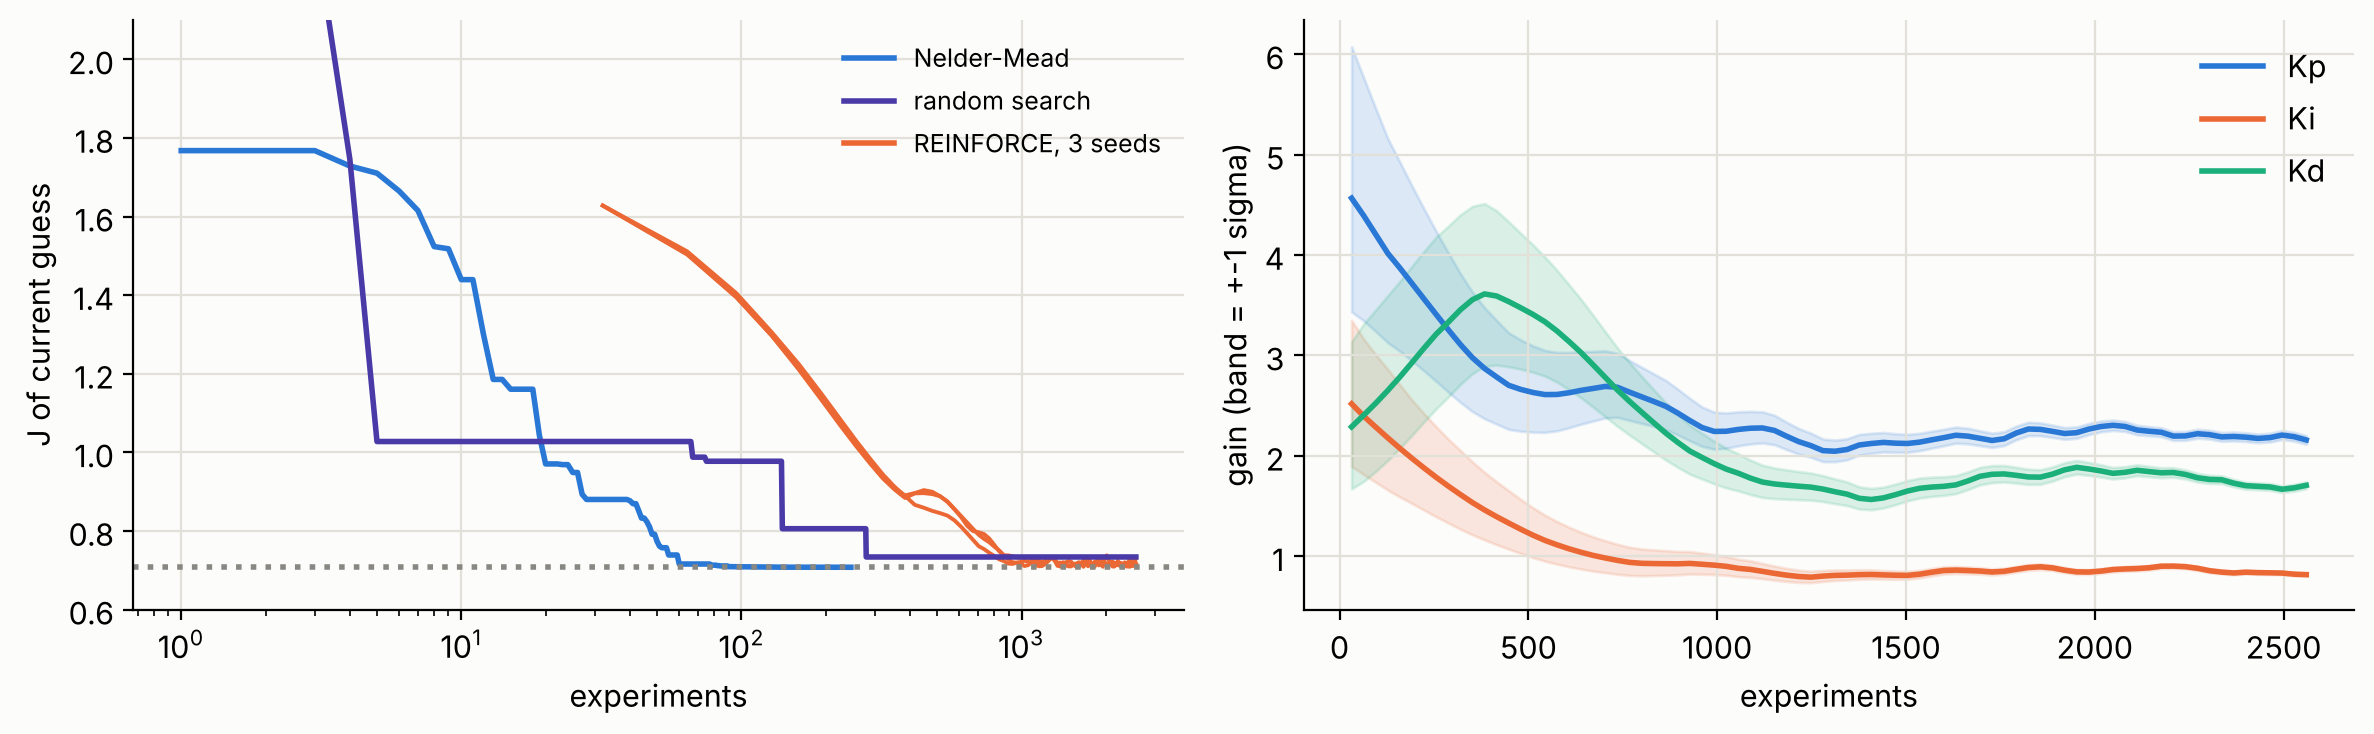

In [14]:
trace = []
def f_nm(lg):
    trace.append(cost_batch([K0], [TAU0], [np.exp(lg)], [Ku], [Tu])[0][0]); return trace[-1]
minimize(f_nm, np.log(g_zn), method="Nelder-Mead", options=dict(xatol=1e-4, fatol=1e-7))
nm_best = np.minimum.accumulate(trace)
rng = np.random.default_rng(3)
lg = rng.uniform(np.log([0.3, 0.05, 0.1]), np.log([12, 6, 6]), (2560, 3))
Jr, mr = cost_batch(np.ones(2560), np.tile(TAU0, (2560, 1)), np.exp(lg), np.full(2560, Ku), np.full(2560, Tu))
print(f"Nelder-Mead : within 1 % after {np.argmax(nm_best <= 1.01*J_opt)+1} experiments, 0 unstable")
print(f"random search: best J {Jr.min():.4f} after 2560 experiments, {100*(1-mr['stable'].mean()):.0f} % of trials unstable")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for h in runs: ax[0].plot(h["evals"], h["J_mu"], color=ORANGE, lw=1.4)
ax[0].plot(np.arange(1, len(nm_best)+1), nm_best, color=BLUE, label="Nelder-Mead")
ax[0].plot(np.arange(1, 2561), np.minimum.accumulate(Jr), color=VIOLET, label="random search")
ax[0].plot([], [], color=ORANGE, label="REINFORCE, 3 seeds"); ax[0].axhline(J_opt, color=MUTED, ls=":")
ax[0].set_xscale("log"); ax[0].set_ylim(0.6, 2.1); ax[0].legend(fontsize=9); ax[0].set_xlabel("experiments"); ax[0].set_ylabel("J of current guess")
h = runs[0]; mu, sg = np.exp(h["mu"]), h["sigma"]
for j, (nm, c) in enumerate(zip(["Kp", "Ki", "Kd"], [BLUE, ORANGE, AQUA])):
    ax[1].plot(h["evals"], mu[:, j], color=c, label=nm)
    ax[1].fill_between(h["evals"], mu[:, j]*np.exp(-sg[:, j]), mu[:, j]*np.exp(sg[:, j]), color=c, alpha=0.15)
ax[1].legend(); ax[1].set_xlabel("experiments"); ax[1].set_ylabel("gain (band = +-1 sigma)")
plt.tight_layout(); plt.show()

**The honest reading.**

* REINFORCE finds the optimum: all three seeds end within a few per cent of the Nelder–Mead value,
  and the result *is* a dramatically better controller than ZN classic.
* It needs about **1163** experiments to get within 1 %. Nelder–Mead needs **78**.
  **For one fixed plant whose experiments are deterministic, a classical optimiser wins by more than
  an order of magnitude.** Do not let anyone tell you otherwise.
* Random search wastes about **20 %** of its experiments on unstable loops. REINFORCE, which
  explores *locally around a stable start*, had one unstable trial in 2 560. On a real plant that
  difference decides whether the method is usable at all.

So why bother with RL? Formulation A is the stepping stone. The payoff comes when the policy can
**generalise**, that is, when one training run produces a tuner for *many* plants. That needs a
plant family.

## 8. A family of plants

ZN is valuable because it is a *rule*: measure two numbers, get gains, for any plant. To learn a
rule we train on many plants. We keep the third-order-lag structure and randomise it:

$$P(s)=\frac{K}{(\tau_1s+1)(\tau_2s+1)(\tau_3s+1)},\qquad K\sim\log\mathcal U[0.5,2],\quad \tau_i\sim\log\mathcal U[0.25,4]\ \text{s}.$$

The nominal plant is one member. Others have one dominant lag and two fast ones, which a
first-order-plus-dead-time engineer would call "easy", or three spread-out lags.

**Features the policy may see.** Only what an engineer can measure before tuning:

* from a relay test, $(K_u,T_u)$;
* from an open-loop step test, the static gain $K$ and the average residence time
  $T_{ar}=\int_0^\infty(1-y/K)\,dt$, which equals $\tau_1+\tau_2+\tau_3$ for this structure.

We feed two **dimensionless** combinations, $\log(KK_u)$ (equal to $\log 8$ for three equal lags,
larger when one lag dominates) and $\log(T_u/T_{ar})$. Because the features, the time axis and the
cost are all dimensionless, a rule learned on these plants is automatically scale-free, just like ZN.

**The per-plant optimum.** To score any rule we need the best achievable $J$ for each test plant.
We get it with a batched cross-entropy method (CEM) that runs on all plants in parallel and was
checked against Nelder–Mead on individual plants. It is a reference that tunes each plant from
scratch, not a deployable method.

In [15]:
def sample_plants(n, rng, k_rng=(0.5, 2.0), tau_rng=(0.4, 2.5)):
    '''Random third-order lags: log-uniform gain and three log-uniform time constants.'''
    K = np.exp(rng.uniform(*np.log(k_rng), n))
    taus = np.exp(rng.uniform(*np.log(tau_rng), (n, 3)))
    KuTu = np.array([ultimate(K[i], taus[i]) for i in range(n)])
    return K, taus, KuTu[:, 0], KuTu[:, 1]


def features(K, Ku, Tu, taus):
    '''What an engineer can measure before tuning: a relay test gives (Ku, Tu); an open-loop
    step test gives K and the average residence time Tar (= t1+t2+t3 for this structure).
    Both features are dimensionless, so the rule is scale-free by construction.'''
    Tar = np.asarray(taus).sum(-1)
    f1 = np.log(K * Ku)            # 8 for three equal lags, larger when one lag dominates
    f2 = np.log(Tu / Tar)
    return np.stack([(f1 - 2.3) / 0.25, (f2 - 0.0) / 0.15], -1)


def make_pool(n, seed, **kw):
    from pid_common import sample_plants
    rng = np.random.default_rng(seed)
    K, taus, Ku, Tu = sample_plants(n, rng, **kw)
    Gzn = np.array([zn_gains(Ku[i], Tu[i]) for i in range(n)])
    Jzn, _ = cost_batch(K, taus, Gzn, Ku, Tu)
    return dict(K=K, taus=taus, Ku=Ku, Tu=Tu, Gzn=Gzn, Jzn=Jzn, F=features(K, Ku, Tu, taus))


def oracle_cem(pool, idx, iters=30, pop=48, elite=8, seed=0):
    '''Per-plant optimum of the log-multipliers by the cross-entropy method, all plants in
    parallel.  This is the "tune every plant from scratch" reference, not a deployable rule.'''
    rng = np.random.default_rng(seed); idx = np.asarray(idx); n = len(idx)
    mu = np.tile(np.log([0.45, 0.3, 0.8]), (n, 1)); sd = np.full((n, 3), 0.4)
    best_J = np.full(n, np.inf); best_lm = mu.copy()
    rep = lambda x: np.repeat(x, pop, 0)
    K, taus, Ku, Tu, Gzn = (rep(pool[k][idx]) for k in ["K", "taus", "Ku", "Tu", "Gzn"])
    for it in range(iters):
        lm = rep(mu) + rep(sd) * rng.standard_normal((n * pop, 3))
        J, _ = cost_batch(K, taus, Gzn * np.exp(lm), Ku, Tu)
        J = J.reshape(n, pop); lm = lm.reshape(n, pop, 3)
        order = np.argsort(J, 1)[:, :elite]
        el = np.take_along_axis(lm, order[..., None], 1)
        mu = el.mean(1); sd = el.std(1) + 0.01
        jb = J[np.arange(n), order[:, 0]]
        better = jb < best_J
        best_J[better] = jb[better]; best_lm[better] = lm[np.arange(n), order[:, 0]][better]
    return best_J, best_lm

In [16]:
t0 = time.time()
TAU_RNG = (0.25, 4.0)
pool = make_pool(4000, 11, tau_rng=TAU_RNG)          # training plants
test = make_pool(200, 209, tau_rng=TAU_RNG)          # never seen during training
J_or, lm_or = oracle_cem(test, np.arange(200))
gm = lambda J: float(np.exp(np.mean(np.log(J / J_or))))
print(f"K*Ku on the test plants: min {np.min(test['K']*test['Ku']):.1f}, median {np.median(test['K']*test['Ku']):.1f}, "
      f"max {np.max(test['K']*test['Ku']):.1f}")
print(f"ZN classic on the test plants: J / J_optimum = {gm(test['Jzn']):.3f} (geometric mean)")
print(f"optimal multipliers on ZN (median over plants): Kp x{np.exp(np.median(lm_or[:,0])):.2f}, "
      f"Ki x{np.exp(np.median(lm_or[:,1])):.2f}, Kd x{np.exp(np.median(lm_or[:,2])):.2f};   {time.time()-t0:.1f} s")
print("correlation of optimal log-multiplier with log(K*Ku):",
      np.round([np.corrcoef(test["F"][:, 0], lm_or[:, j])[0, 1] for j in range(3)], 2))

K*Ku on the test plants: min 8.0, median 11.2, max 28.3
ZN classic on the test plants: J / J_optimum = 2.575 (geometric mean)
optimal multipliers on ZN (median over plants): Kp x0.41, Ki x0.23, Kd x0.76;   36.3 s
correlation of optimal log-multiplier with log(K*Ku): [-0.94 -1.   -0.76]


Two facts set up the rest of the notebook. On average ZN classic costs about **2.57×** the best
achievable $J$, so there is a lot to gain. And the optimal correction to ZN is **not constant**: it
correlates strongly with $\log(KK_u)$, especially for $K_i$. A single better table of three numbers
will help, but a rule that *reads the plant* should help more.

## 9. Formulation B — learning a tuning rule

**Policy.** A small network maps features to the *mean* log-multipliers on the ZN gains,
$a=\log(K/K_\text{ZN})$, with a learned state-independent $\sigma$. Parameterising the action
relative to ZN does three things:

1. the network's output is $\mathcal O(1)$ whatever the plant's scale;
2. we initialise the output layer to the multipliers $(0.45,0.30,0.80)$ that worked on the nominal
   plant, which means every early experiment is a sensible, stable controller (training starts with
   **0 %** unstable trials);
3. the learned policy is interpretable: you can plot it as "how much to scale each ZN gain".

**Reward.** $r=\log(J_\text{ZN}/J)$, the log-improvement over ZN on that plant. Using a log ratio
matters: raw $-J$ varies across plants for reasons the policy cannot control (some plants are simply
harder), and that variance would swamp the learning signal.

**Baseline.** With a context, the right baseline is state-dependent, $V(s)\approx\mathbb E[r\mid s]$.
A small critic learns it by regression, and the advantage is $r-V(s)$. The loss is the usual
$-\log\pi(a\mid s)\,A$ plus $\tfrac12(V-r)^2$.

**Two variants, same code.** `context=False` zeroes the input, so the policy can only learn **three
constants**. It is literally a re-fitted ZN table, which shows how much is gained from the features
themselves.

In [17]:
class RulePolicy(nn.Module):
    '''Maps plant features to log-multipliers on the Ziegler-Nichols gains.
    With context=False it ignores the plant: it learns one set of constants (a "better ZN").'''
    def __init__(self, context=True, hidden=32, init=(np.log(0.45), np.log(0.3), np.log(0.8))):
        super().__init__()
        self.context = context
        self.net = nn.Sequential(nn.Linear(2, hidden), nn.Tanh(), nn.Linear(hidden, 3))
        nn.init.zeros_(self.net[2].weight)
        with torch.no_grad():
            self.net[2].bias.copy_(torch.tensor(init, dtype=torch.float32))
        self.log_std = nn.Parameter(torch.full((3,), np.log(0.25)))
        self.critic = nn.Sequential(nn.Linear(2, hidden), nn.Tanh(), nn.Linear(hidden, 1))

    def forward(self, f):
        if not self.context:
            f = torch.zeros_like(f)
        return self.net(f), self.log_std.exp().expand(f.shape[0], 3)


def train_rule(pool, context=True, iters=250, batch=128, lr=3e-3, seed=0, log_every=10):
    '''pool: dict of arrays K, taus, Ku, Tu, F (features), Jzn. One episode = one plant drawn
    from the pool, one sampled gain vector, one step test.  Reward = log(J_ZN / J).'''
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    pol = RulePolicy(context)
    opt = torch.optim.Adam(pol.parameters(), lr=lr)
    hist = dict(it=[], reward=[], unstable=[])
    n = len(pool["K"])
    for it in range(iters):
        idx = rng.integers(0, n, batch)
        f = torch.tensor(pool["F"][idx], dtype=torch.float32)
        mean, std = pol(f)
        dist = torch.distributions.Normal(mean, std)
        a = dist.sample()
        G = pool["Gzn"][idx] * np.exp(a.numpy())
        J, info = cost_batch(pool["K"][idx], pool["taus"][idx], G, pool["Ku"][idx], pool["Tu"][idx])
        R = torch.tensor(np.log(pool["Jzn"][idx] / J), dtype=torch.float32)
        V = pol.critic(f).squeeze(-1) if context else torch.zeros(batch)
        adv = R - V.detach()
        adv = (adv - adv.mean()) / (adv.std() + 1e-8)
        loss = -(dist.log_prob(a).sum(-1) * adv).mean()
        if context:
            loss = loss + 0.5 * ((V - R) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            pol.log_std.clamp_(np.log(0.03), np.log(0.5))
        if it % log_every == 0 or it == iters - 1:
            hist["it"].append(it); hist["reward"].append(R.mean().item())
            hist["unstable"].append(1 - info["stable"].mean())
    return pol, {k: np.array(v) for k, v in hist.items()}


def rule_gains(pol, F, Gzn):
    with torch.no_grad():
        mean, _ = pol(torch.tensor(F, dtype=torch.float32))
    return Gzn * np.exp(mean.numpy())

In [18]:
pols, hist_rule = {}, {}
for ctx, name in [(False, "constant rule"), (True, "contextual rule")]:
    t0 = time.time()
    pols[name], hist_rule[name] = train_rule(pool, ctx, iters=250, batch=128)
    Gp = rule_gains(pols[name], test["F"], test["Gzn"])
    J, _ = cost_batch(test["K"], test["taus"], Gp, test["Ku"], test["Tu"])
    print(f"{name:16s}: 32 000 episodes in {time.time()-t0:4.1f} s   test J / J_optimum = {gm(J):.3f}   "
          f"(unstable in first batch: {hist_rule[name]['unstable'][0]:.0%})")
print("learned constants (x ZN):  Kp %.3f   Ki %.3f   Kd %.3f" %
      tuple(np.exp(pols["constant rule"].net[2].bias.detach().numpy())))

constant rule   : 32 000 episodes in  8.8 s   test J / J_optimum = 1.149   (unstable in first batch: 0%)


contextual rule : 32 000 episodes in  7.0 s   test J / J_optimum = 1.024   (unstable in first batch: 0%)
learned constants (x ZN):  Kp 0.448   Ki 0.291   Kd 0.806


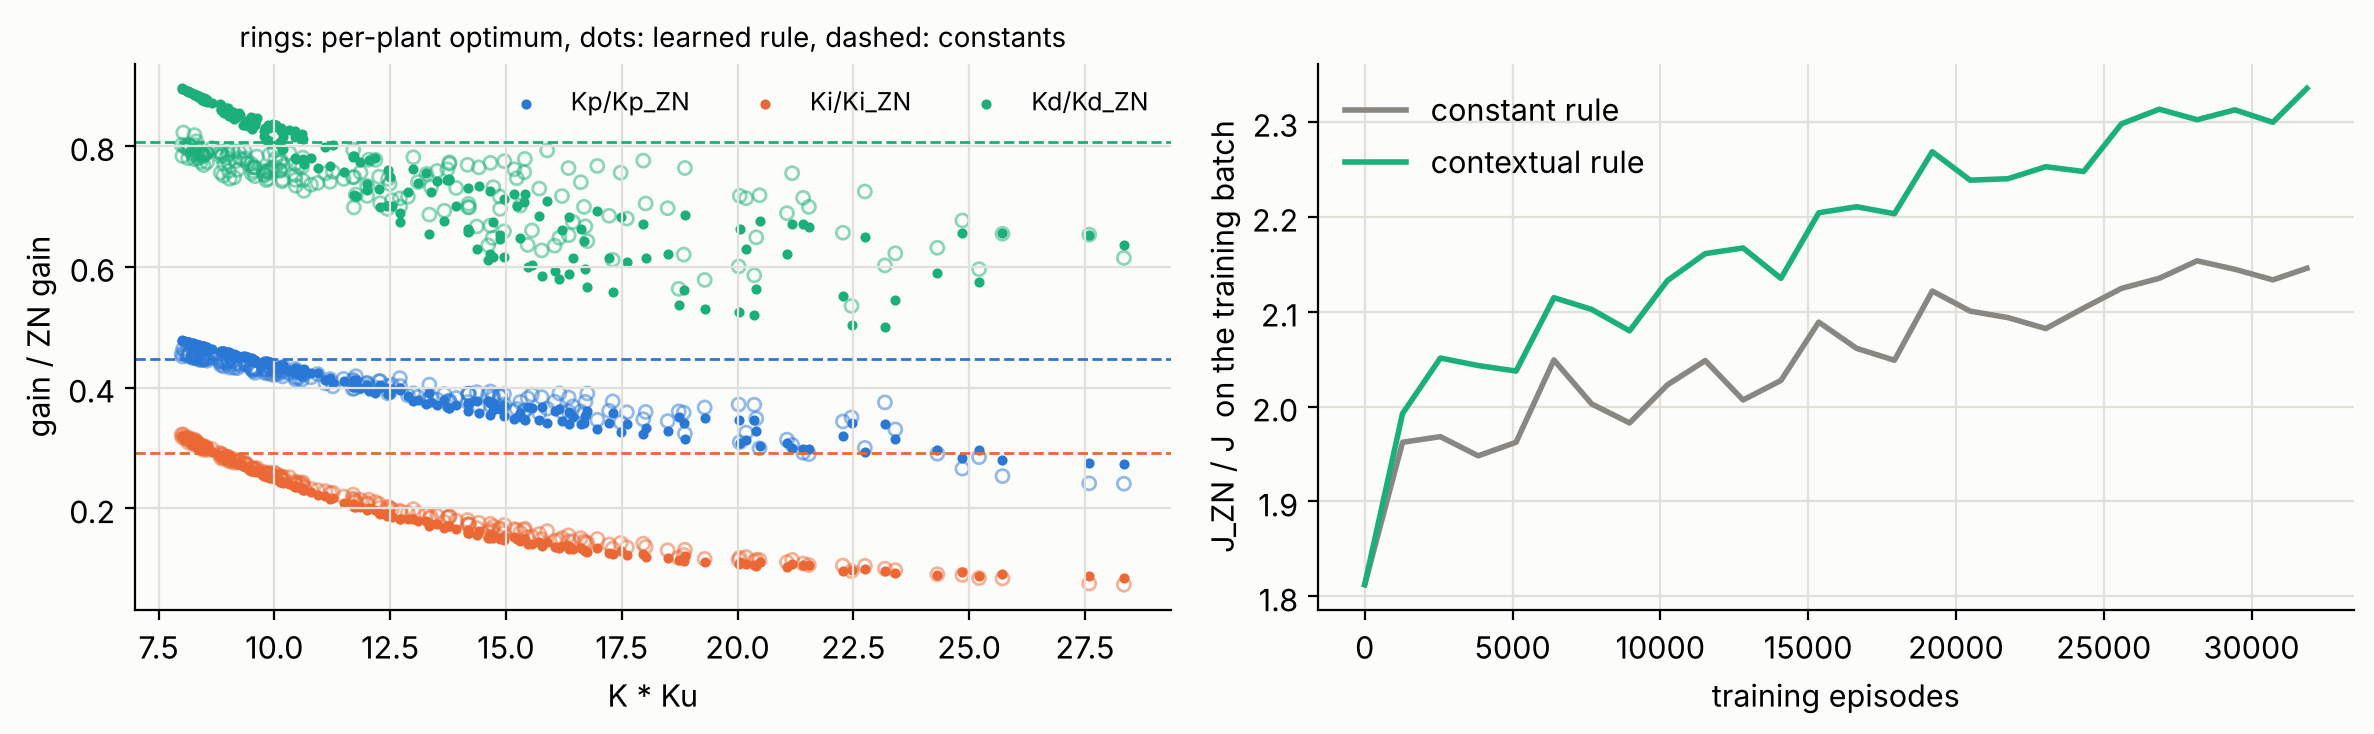

In [19]:
lm_rule = np.log(rule_gains(pols["contextual rule"], test["F"], test["Gzn"]) / test["Gzn"])
const = np.exp(pols["constant rule"].net[2].bias.detach().numpy())
KKu = test["K"] * test["Ku"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for j, (nm, c) in enumerate(zip(["Kp", "Ki", "Kd"], [BLUE, ORANGE, AQUA])):
    ax[0].scatter(KKu, np.exp(lm_or[:, j]), s=22, facecolor="none", edgecolor=c, alpha=0.5)
    ax[0].scatter(KKu, np.exp(lm_rule[:, j]), s=7, color=c, label=f"{nm}/{nm}_ZN")
    ax[0].axhline(const[j], color=c, ls="--", lw=1)
ax[0].set_xlabel("K * Ku"); ax[0].set_ylabel("gain / ZN gain"); ax[0].legend(fontsize=9, ncol=3)
ax[0].set_title("rings: per-plant optimum, dots: learned rule, dashed: constants", fontsize=10)
for name, c in [("constant rule", MUTED), ("contextual rule", AQUA)]:
    ax[1].plot(hist_rule[name]["it"] * 128, np.exp(hist_rule[name]["reward"]), color=c, label=name)
ax[1].set_xlabel("training episodes"); ax[1].set_ylabel("J_ZN / J  on the training batch"); ax[1].legend()
plt.tight_layout(); plt.show()

**What the network learned.** Every multiplier is below 1, so ZN classic is too aggressive on every
plant in the family. The integral gain needs the biggest cut (×0.3 for three equal lags, down to
about ×0.1 when one lag dominates) and the cut deepens steadily as $KK_u$ grows. The rule follows
the per-plant optimum (rings) closely for $K_p$ and $K_i$. It is noisier for $K_d$, where the cost
surface is flatter, so the precise value matters less.

The constant rule gets to **1.15×** the optimum on unseen plants. Reading the plant takes the
contextual rule to **1.024×**. Once trained, the rule costs **one** relay test and **one** step
test per new plant and needs no tuning experiments at all.

## 10. Formulation C — an iterative tuner trained with PPO

A rule must commit before it sees the closed loop. An engineer does better: try some gains, look at
the response, adjust, and repeat. Formulation C turns that loop into an MDP:

* **State** (12 numbers): the current log-multipliers (3); the measured metrics of the last
  experiment, i.e. $\log\text{IAE}_r$, $\log\text{IAE}_d$, overshoot, $\log$ normalised noise gain,
  $\log(J/J_\text{ZN})$ and a stability flag (6); the plant features (2); and the fraction of the
  experiment budget used (1).
* **Action**: a change to the three log-multipliers, clipped to ±0.4 (×0.67 to ×1.49 per step), so
  the agent can only make *moderate* moves, as a careful engineer would.
* **Reward**: $\log(J_\text{prev}/J_\text{new})$. The return over the episode telescopes to
  $\log(J_\text{ZN}/J_\text{final})$, so maximising the return means *finishing* as well as possible,
  and the per-step reward gives dense credit for each improvement.
* **Episode**: start at ZN classic and run 6 experiments.

**Why PPO.** This is a genuine sequential problem: an early experiment that probes the plant can
pay off later. PPO (Schulman et al., 2017) is the robust default for that. Rollouts of 128 parallel
tuning sessions are followed by 8 epochs of clipped-ratio updates. Advantages come from GAE
($\lambda=0.95$, $\gamma=1$ because the horizon is short and fixed, and time is part of the state).

In [20]:
class TuningEnv:
    '''A batch of tuning sessions.  Each step = one closed-loop experiment on the plant.
    State : current log-multipliers on ZN, the measured metrics of the last experiment,
            the plant features, and the fraction of the budget used.
    Action: a change of the three log-multipliers, clipped to +-0.4 per step.
    Reward: log(J_prev / J_new)  - the improvement this experiment bought.'''
    H = 6
    STEP_MAX = 0.4

    def __init__(self, pool, n, rng):
        self.pool, self.n, self.rng = pool, n, rng

    def _measure(self):
        G = self.Gzn * np.exp(self.lm)
        J, info = cost_batch(self.K, self.taus, G, self.Ku, self.Tu)
        self.J = J
        stab = info["stable"]
        m = np.stack([np.where(stab, np.log(info["iae_r"] + 1e-3), 0),
                      np.where(stab, np.log(info["iae_d"] + 1e-3), 0),
                      np.where(stab, np.minimum(info["os"], 1.0), 1.0),
                      np.where(stab, np.log(info["noise"] / (self.K * self.Ku)), 0),
                      np.log(J / self.Jzn), stab.astype(float)], -1)
        return m

    def obs(self):
        return np.concatenate([self.lm, self.m, self.F,
                               np.full((self.n, 1), self.t / self.H)], -1).astype(np.float32)

    def reset(self, idx=None):
        if idx is None:
            idx = self.rng.integers(0, len(self.pool["K"]), self.n)
        self.n = len(idx)
        p = self.pool
        self.K, self.taus, self.Ku, self.Tu = p["K"][idx], p["taus"][idx], p["Ku"][idx], p["Tu"][idx]
        self.F, self.Gzn, self.Jzn = p["F"][idx], p["Gzn"][idx], p["Jzn"][idx]
        self.lm = np.zeros((self.n, 3)); self.t = 0          # start at Ziegler-Nichols
        self.m = self._measure()
        return self.obs()

    def step(self, a):
        J_prev = self.J.copy()
        self.lm = np.clip(self.lm + np.clip(a, -self.STEP_MAX, self.STEP_MAX), -2.5, 1.0)
        self.m = self._measure(); self.t += 1
        r = np.log(J_prev / self.J)
        return self.obs(), r, self.t >= self.H


class ActorCritic(nn.Module):
    def __init__(self, obs_dim=12, hidden=64):
        super().__init__()
        self.pi = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(),
                                nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, 3))
        self.v = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(),
                               nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, 1))
        nn.init.normal_(self.pi[4].weight, std=0.01); nn.init.zeros_(self.pi[4].bias)
        self.log_std = nn.Parameter(torch.full((3,), np.log(0.15)))

    def dist(self, o):
        return torch.distributions.Normal(self.pi(o), self.log_std.exp())


def train_ppo(pool, iters=120, n_env=128, epochs=8, mb=256, lr=1e-3, gamma=1.0, lam=0.95,
              clip=0.2, seed=0, log_every=5):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    env = TuningEnv(pool, n_env, rng); ac = ActorCritic()
    opt = torch.optim.Adam(ac.parameters(), lr=lr)
    hist = dict(it=[], final_ratio=[], ret=[])
    H = env.H
    for it in range(iters):
        O, A, LP, R, V = [], [], [], [], []
        o = env.reset()
        for t in range(H):
            ot = torch.tensor(o)
            with torch.no_grad():
                d = ac.dist(ot); a = d.sample(); lp = d.log_prob(a).sum(-1); v = ac.v(ot).squeeze(-1)
            o2, r, done = env.step(a.numpy())
            O.append(ot); A.append(a); LP.append(lp); R.append(torch.tensor(r, dtype=torch.float32)); V.append(v)
            o = o2
        # GAE (episode ends after H experiments; time is in the state, so no bootstrap)
        adv = torch.zeros(H, n_env); last = torch.zeros(n_env)
        for t in reversed(range(H)):
            v_next = V[t + 1] if t + 1 < H else torch.zeros(n_env)
            delta = R[t] + gamma * v_next - V[t]
            last = delta + gamma * lam * last; adv[t] = last
        ret = adv + torch.stack(V)
        O, A, LP = torch.cat(O), torch.cat(A), torch.cat(LP)
        adv_f, ret_f = adv.reshape(-1), ret.reshape(-1)
        adv_f = (adv_f - adv_f.mean()) / (adv_f.std() + 1e-8)
        N = len(O)
        for _ in range(epochs):
            perm = torch.randperm(N)
            for s in range(0, N, mb):
                b = perm[s:s + mb]
                d = ac.dist(O[b]); lp = d.log_prob(A[b]).sum(-1)
                ratio = (lp - LP[b]).exp()
                pl = -torch.min(ratio * adv_f[b], ratio.clamp(1 - clip, 1 + clip) * adv_f[b]).mean()
                vl = ((ac.v(O[b]).squeeze(-1) - ret_f[b]) ** 2).mean()
                loss = pl + 0.5 * vl - 0.001 * d.entropy().sum(-1).mean()
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(ac.parameters(), 0.5); opt.step()
        if it % log_every == 0 or it == iters - 1:
            hist["it"].append(it)
            hist["final_ratio"].append(float(np.exp(np.mean(np.log(env.J / env.Jzn)))))
            hist["ret"].append(float(torch.stack(R).sum(0).mean()))
    return ac, {k: np.array(v) for k, v in hist.items()}


def run_ppo_tuner(ac, pool, idx, deterministic=True):
    '''Roll the trained tuner on given plants; returns J after each experiment (n, H+1).'''
    env = TuningEnv(pool, len(idx), np.random.default_rng(0))
    o = env.reset(np.asarray(idx)); Js = [env.J.copy()]; LM = [env.lm.copy()]
    for t in range(env.H):
        with torch.no_grad():
            d = ac.dist(torch.tensor(o)); a = d.mean if deterministic else d.sample()
        o, r, done = env.step(a.numpy()); Js.append(env.J.copy()); LM.append(env.lm.copy())
    return np.stack(Js, 1), np.stack(LM, 1)

In [21]:
t0 = time.time()
ac, hp = train_ppo(pool, iters=120, n_env=128)
print(f"PPO: {120*128*6:,} simulated experiments in {time.time()-t0:.1f} s")
Js, LM = run_ppo_tuner(ac, test, np.arange(200))
ratio_by_step = [gm(Js[:, k]) for k in range(Js.shape[1])]
print("J / J_optimum after each experiment (0 = ZN start):", np.round(ratio_by_step, 3))
print("unstable experiments while tuning the 200 test plants:", int((Js[:, 1:] >= J_FAIL).sum()))

PPO: 92,160 simulated experiments in 29.5 s


J / J_optimum after each experiment (0 = ZN start): [2.575 2.046 1.638 1.371 1.194 1.07  1.004]
unstable experiments while tuning the 200 test plants: 0


example plant: K = 0.57, lags = [0.26 2.39 3.8 ] s, K*Ku = 28.3


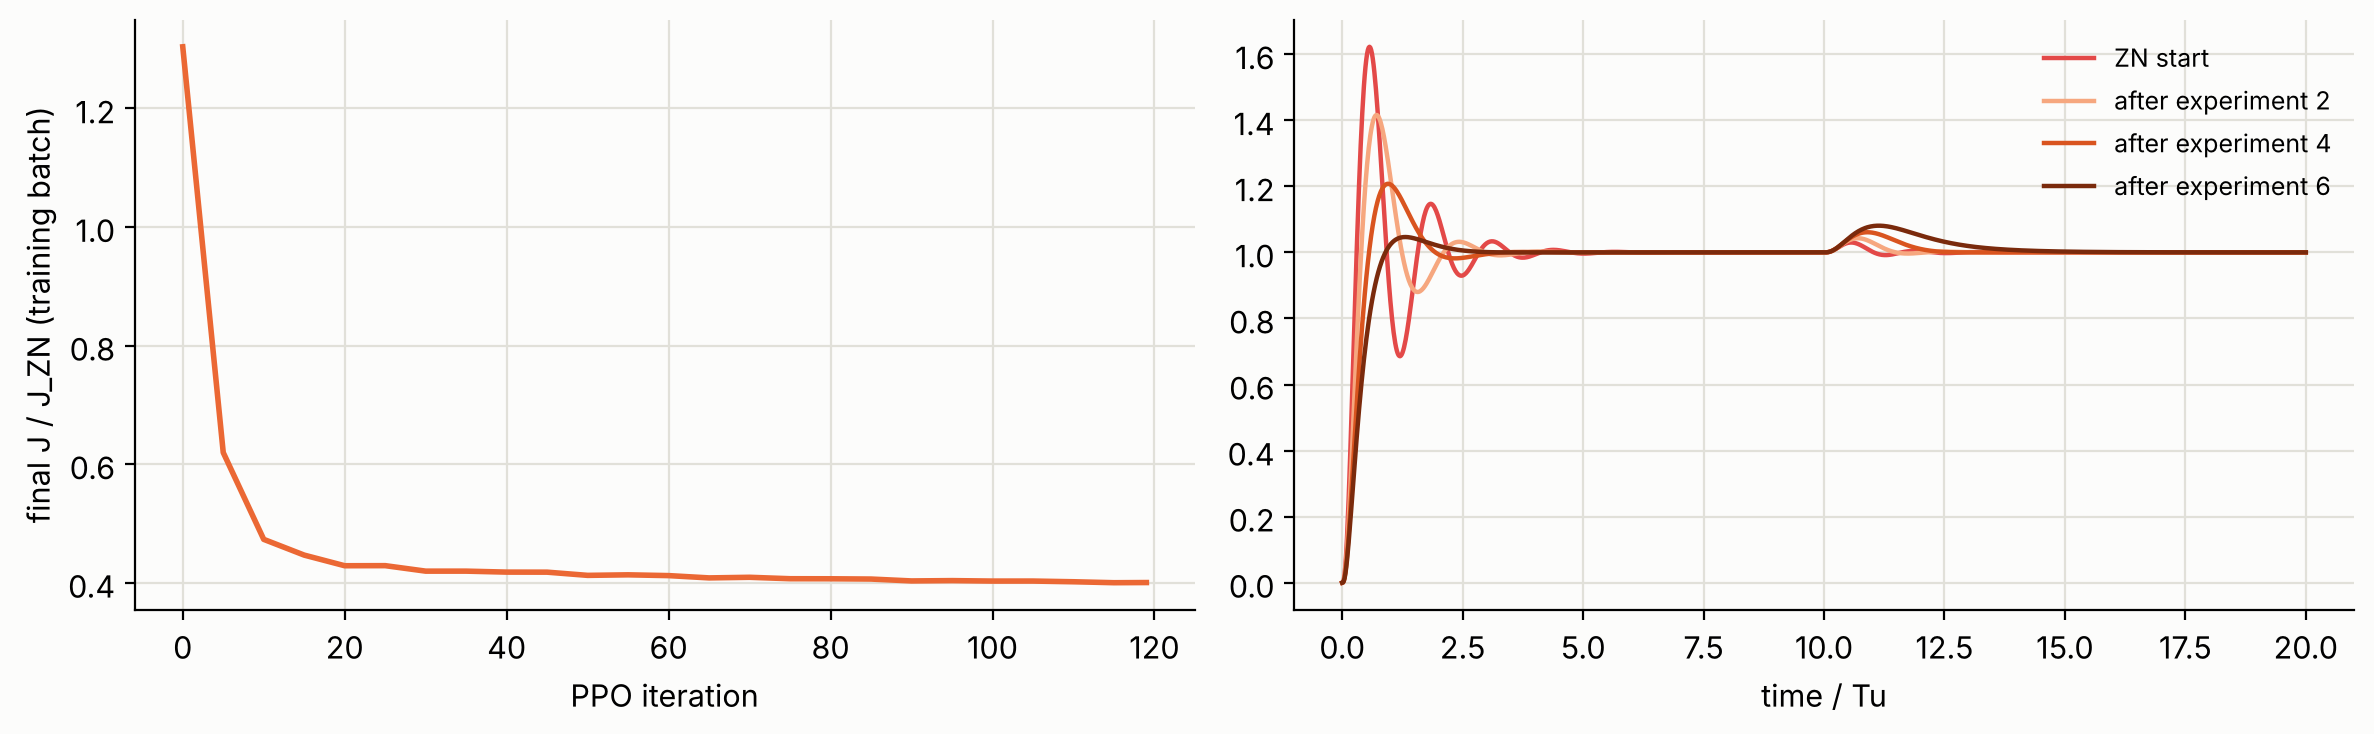

log-multipliers on this plant, step by step:
 [[ 0.    0.    0.  ]
 [-0.2  -0.4  -0.14]
 [-0.46 -0.8  -0.24]
 [-0.72 -1.2  -0.32]
 [-0.97 -1.6  -0.38]
 [-1.18 -2.   -0.43]
 [-1.35 -2.4  -0.48]]


In [22]:
ex = int(np.argmax(cost_batch(test["K"], test["taus"], rule_gains(pols["constant rule"], test["F"], test["Gzn"]),
                              test["Ku"], test["Tu"])[0] /
                   cost_batch(test["K"], test["taus"], rule_gains(pols["contextual rule"], test["F"], test["Gzn"]),
                              test["Ku"], test["Tu"])[0]))
print("example plant: K = %.2f, lags = %s s, K*Ku = %.1f" % (test["K"][ex], np.round(test["taus"][ex], 2), KKu[ex]))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(hp["it"], hp["final_ratio"], color=ORANGE); ax[0].set_xlabel("PPO iteration")
ax[0].set_ylabel("final J / J_ZN (training batch)")
for k, c in zip([0, 2, 4, 6], [RED, "#f6a77f", "#d9541f", "#7a2a0c"]):
    s = simulate(test["K"][ex], test["taus"][ex], test["Gzn"][ex] * np.exp(LM[ex, k]))
    ax[1].plot(s["t"] / s["Tu"], s["y"], color=c, lw=1.6, label="ZN start" if k == 0 else f"after experiment {k}")
ax[1].set_xlabel("time / Tu"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
print("log-multipliers on this plant, step by step:\n", np.round(LM[ex], 2))

**Reading the result.** After 6 experiments the PPO tuner reaches **1.004×** the per-plant
optimum. That beats the contextual rule (**1.024×**), which never sees the closed loop, and it is
within half a per cent of tuning every plant from scratch with thousands of experiments. In the
example, every step lowers the overshoot and the ringing a little further. The agent has learned a
*procedure* ("this response overshoots and rings, so back off $K_i$ and $K_p$"), not a single answer.

Look at the printed log-multipliers, though. On this plant the $K_i$ change is $-0.4$ at **every**
step, which is the action limit. The agent wants to move faster than we let it, and the final $K_i$
is set by the budget, not by the agent's judgement. That is a design trade-off between safety
(small moves) and speed (few experiments), and exercise 7 explores it.

This is what an RL tuner is for: the expensive learning happens **once, in simulation, across a
family of plants**. Each new loop on the plant floor then costs a relay test plus a handful of
closed-loop experiments, roughly what a commissioning engineer would spend anyway.

## 11. Head to head on 200 unseen plants

All methods are scored by the same $J$ on the same 200 test plants, as a geometric mean of
$J/J_\text{optimum}$ (1.00 = as good as tuning each plant from scratch).

In [23]:
rows = []
for rule in ["classic", "some_os", "no_os"]:
    Gz = np.array([zn_gains(test["Ku"][i], test["Tu"][i], rule) for i in range(200)])
    rows.append((f"ZN {rule}", cost_batch(test["K"], test["taus"], Gz, test["Ku"], test["Tu"])[0], "relay test"))
for name in ["constant rule", "contextual rule"]:
    Gp = rule_gains(pols[name], test["F"], test["Gzn"])
    rows.append((f"RL {name}", cost_batch(test["K"], test["taus"], Gp, test["Ku"], test["Tu"])[0],
                 "relay test" if name == "constant rule" else "relay + step test"))
rows.append(("RL PPO iterative tuner", Js[:, -1], "relay + step + 6 closed-loop tests"))
rows.append(("per-plant optimum (CEM)", J_or, "1 440 closed-loop tests per plant"))
print(f"{'method':26s} {'J/J_opt':>8s} {'worst':>7s}   experiments per new plant")
for name, J, cost in rows:
    r = J / J_or
    print(f"{name:26s} {gm(J):8.3f} {r.max():7.2f}   {cost}")

method                      J/J_opt   worst   experiments per new plant
ZN classic                    2.575    2.64   relay test
ZN some_os                    1.434    1.83   relay test
ZN no_os                      1.483    1.79   relay test
RL constant rule              1.149    1.37   relay test
RL contextual rule            1.024    1.04   relay + step test
RL PPO iterative tuner        1.004    1.04   relay + step + 6 closed-loop tests
per-plant optimum (CEM)       1.000    1.00   1 440 closed-loop tests per plant


| method | what it needs on a new plant | J / optimum |
|---|---|---|
| ZN classic | relay test | 2.57 |
| ZN some overshoot | relay test | 1.43 |
| RL constant rule | relay test | 1.15 |
| RL contextual rule | relay + step test | 1.024 |
| RL PPO tuner | + 6 closed-loop experiments | 1.004 |

The ranking is the lesson. **More information about the plant buys better gains.** A better table
of constants already helps a lot. Plant features help more, and closed-loop feedback helps most. RL
is the tool that turns that information into gains *without anyone deriving the mapping by hand*,
which is exactly what Ziegler and Nichols did in 1942 with a slide rule and a lot of experiments.

## 12. Verify before you deploy

A learned controller is still a linear PID, so we can and must check it with classical tools.
Never deploy gains that you have only judged by their reward. Gain margin $g_m$, phase margin
$\varphi_m$ and the peak of the sensitivity function $M_s=\max_\omega|1/(1+L(j\omega))|$ ($M_s\le
1.4$–$2$ is the usual robustness target) come straight from the loop transfer function
$L=C(j\omega)P(j\omega)$.

In [24]:
def loop_tf(w, K, taus, gains, Tf):
    s = 1j * w
    P = K / np.prod([(t * s + 1) for t in taus], axis=0)
    Kp, Ki, Kd = gains
    return P * (Kp + Ki / s + Kd * s / (Tf * s + 1))


def margins(K, taus, gains, Tu):
    w = np.logspace(-3, 3, 200001); L = loop_tf(w, K, taus, gains, TF_TU * Tu)
    ph = np.unwrap(np.angle(L)); mag = np.abs(L)
    i180 = np.where(np.diff(np.sign(ph + np.pi)))[0]
    gm = 1 / mag[i180[0]] if len(i180) else np.inf
    ic = np.where(np.diff(np.sign(mag - 1)))[0]
    pm = np.degrees(np.pi + ph[ic[-1]]) if len(ic) else np.inf
    Ms = np.max(1 / np.abs(1 + L))
    return dict(gm=float(gm), pm=float(pm), Ms=float(Ms))


g_rf = np.exp(runs[0]["mu"][-1])
for name, g in [("ZN classic", g_zn), ("ZN some overshoot", zn_gains(Ku, Tu, "some_os")),
                ("REINFORCE", g_rf), ("Nelder-Mead optimum", g_opt)]:
    m = margins(K0, TAU0, g, Tu)
    print(f"{name:20s}  gain margin {m['gm']:5.2f}   phase margin {m['pm']:5.1f} deg   Ms {m['Ms']:.2f}")

ZN classic            gain margin  4.51   phase margin  27.6 deg   Ms 2.43
ZN some overshoot     gain margin  7.85   phase margin  66.5 deg   Ms 1.48
REINFORCE             gain margin 11.37   phase margin  69.8 deg   Ms 1.37
Nelder-Mead optimum   gain margin 11.16   phase margin  69.0 deg   Ms 1.38


ZN classic has a phase margin of only about **28°** and $M_s\approx$ **2.43**, which is why it
rings and why it sat near the cliff in §5. The RL-tuned controller has about **70°** and
$M_s\approx$ **1.37**, comfortably robust, even though robustness was never written into the
reward. It appeared indirectly through the overshoot and noise-gain terms. Do not count on such
luck in general: if robustness matters, put $M_s$ in the reward or reject candidates that violate
it (exercise 6).

## 13. Protocol: what to remember

1. **Write the cost first, and write all of it.** Tracking, disturbance rejection, overshoot and
   actuator/noise effort. A missing term will be exploited (§4).
2. **Start from ZN, or any known-stable controller.** Parameterise actions relative to it and in
   log-gains. This removes negative gains, fixes the scaling and makes early exploration safe.
3. **Handle instability explicitly.** Check closed-loop eigenvalues (or margins) before the
   experiment, and charge a fixed penalty. Expect a cliff, not a slope.
4. **On one known plant, use an optimiser.** Nelder–Mead needed 78 experiments, REINFORCE
   about 1163. RL pays off when one training run serves many plants.
5. **Make everything dimensionless** (time in $T_u$, gains via $K$ or ZN, reward as a log ratio) so
   a single policy can generalise across a family.
6. **Give the policy what an engineer would measure**: relay-test and step-test features, and in the
   iterative setting the metrics of the last experiment.
7. **Score on unseen plants against a per-plant optimum**, not just against ZN.
8. **Verify the final gains classically**: margins, $M_s$ and a step test, before they touch
   hardware.
9. **Train in simulation, fine-tune on the plant.** Every experiment here was simulated. On a real
   loop, exploration costs product, time and wear. A policy pre-trained on a randomised plant family
   is what makes the on-plant budget small (Lawrence et al., 2022, needed about 40 min on a real
   tank system).

## 14. Exercises

1. **Actuator saturation and wind-up.** Clip $u$ to $[-2, 4]$ in `simulate` and `cost_batch`. The
   loop is no longer linear, so the exact ZOH update must be applied with the saturated input.
   Re-run §7. Does ZN classic now look worse or better relative to the optimum? Add back-calculation
   anti-wind-up and repeat.
2. **Derivative on measurement.** Change the controller so that the D-term acts on $-y$ instead of
   $e$ (no derivative kick). Which optimal gains change, and why does the noise-gain term no longer
   tell the whole story?
3. **ITAE instead of IAE.** Replace both IAE terms by $\int t|e|\,dt/T_u^2$. Predict how the optimal
   set-point response changes before you run it.
4. **Out-of-distribution plants.** Add a dead time $L=0.3T_{ar}$, or a fourth lag, to the test plants
   only (you will need a Padé approximation or an extra state). Which degrades more, the contextual
   rule or the PPO tuner? Explain using what each policy observes.
5. **Noisy experiments.** Add Gaussian measurement noise to $y$ and compute the noise term as the
   standard deviation of $\Delta u$. The reward is now stochastic. Compare Nelder–Mead and REINFORCE
   again with a fixed budget. Which suffers more, and why?
6. **A robustness constraint.** Reject any candidate with $M_s>1.6$ *before* running the experiment
   (treat it like instability). How much $J$ does the constraint cost on the nominal plant, and on the
   test family?
7. **Budget.** Retrain the PPO tuner with $H=3$ and $H=10$ experiments. Plot the final $J/J_\text{opt}$
   against $H$. Is there a point beyond which more experiments stop helping?
8. **CEM as the policy optimiser.** Replace REINFORCE in §7 by the cross-entropy method (`oracle_cem`
   on a single plant). Compare the number of experiments and unstable trials. Under what conditions
   would you prefer each?

## 15. References

* J. G. Ziegler and N. B. Nichols, "Optimum settings for automatic controllers," *Trans. ASME* **64**,
  759–768 (1942).
* K. J. Åström and T. Hägglund, "Automatic tuning of simple regulators with specifications on phase
  and amplitude margins," *Automatica* **20**(5), 645–651 (1984). The relay test.
* K. J. Åström and T. Hägglund, *Advanced PID Control*, ISA (2006). Filtered derivative, $M_s$,
  wind-up.
* R. J. Williams, "Simple statistical gradient-following algorithms for connectionist reinforcement
  learning," *Machine Learning* **8**, 229–256 (1992). REINFORCE.
* J. Schulman, P. Moritz, S. Levine, M. Jordan and P. Abbeel, "High-dimensional continuous control
  using generalized advantage estimation," *ICLR* (2016).
* J. Schulman, F. Wolski, P. Dhariwal, A. Radford and O. Klimov, "Proximal policy optimization
  algorithms," arXiv:1707.06347 (2017).
* T. Salimans, J. Ho, X. Chen, S. Sidor and I. Sutskever, "Evolution strategies as a scalable
  alternative to reinforcement learning," arXiv:1703.03864 (2017).
* R. Y. Rubinstein, "The cross-entropy method for combinatorial and continuous optimization,"
  *Methodology and Computing in Applied Probability* **1**, 127–190 (1999).
* N. P. Lawrence, G. E. Stewart, P. D. Loewen, M. G. Forbes, J. U. Backström and R. B. Gopaluni,
  "Reinforcement learning based design of linear fixed structure controllers," IFAC World Congress
  (2020), arXiv:2005.04537. PID tuning by random-search policy gradients.
* N. P. Lawrence, M. G. Forbes, P. D. Loewen, D. G. McClement, J. U. Backström and R. B. Gopaluni,
  "Deep reinforcement learning with shallow controllers: an experimental application to PID tuning,"
  *Control Engineering Practice* **121**, 105046 (2022).
* O. Dogru, K. Velswamy, F. Ibrahim, Y. Wu, A. S. Sundaramoorthy, B. Huang, S. Xu, M. Nixon and
  N. Bell, "Reinforcement learning approach to autonomous PID tuning," *Computers & Chemical
  Engineering* **161**, 107760 (2022).
* J. A. van Niekerk, J. D. le Roux and I. K. Craig, "Reinforcement learning based automatic tuning of
  PID controllers in multivariable grinding mill circuits," *Control Engineering Practice* **165**,
  106522 (2025). PPO on a MIMO process.
* R. S. Sutton and A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed., MIT Press (2018),
  ch. 13.
* PyTorch documentation: `torch.distributions` and `torch.nn` — https://pytorch.org/docs/stable/

In [25]:
print(f"total notebook runtime: {time.time() - T_START:.0f} s")

total notebook runtime: 114 s


Generated by Claude and customized by

<div align="center">
<img src="https://raw.githubusercontent.com/dewdotninja/sharing-github/refs/heads/master/dewninja_logo50.jpg" alt="dewninja"/>
</div>
<div align="center">dew.ninja 2026</div>